# 08 — What actually moves validation: an experiment report

Everything in `changes.md` §8 and §9 answered *"is the model too small or trained too
briefly?"*. Both answers were no. This notebook asks the questions that are left, in
**rising order of cost**, and writes every answer to `outputs/exp08/<name>.json`.

| # | experiment | what it tests | cost |
|---|---|---|---|
| 0 | data audit | the class distribution per split, measured not assumed | seconds, no GPU |
| 1 | the metric | how much of the 51% is the mIoU *definition* | seconds, no GPU |
| 2 | free gains | test-time augmentation and 12-month averaging on the weights already trained | ~5 min |
| 3 | baseline | this notebook's own reference run, on the tiles as they are now | ~8 min |
| 4 | loss | Dice, Lovász-Softmax and focal against weighted cross-entropy | ~25 min |
| 5 | sampling | oversampling rare-class tiles instead of only re-weighting the loss | ~8 min |
| 6 | **multi-temporal input** | a 3-month window, and month + annual statistics | ~20 min build + ~20 min |
| 7 | cross-validation | 5 folds over whole regions — honest error bars, and 80% of the data in training | ~45 min |
| 8 | pretrained encoder | the ImageNet comparison `design.md` promised and never ran | ~10 min |

**Read this before running.**

- **Every experiment is independent and resumable.** A finished one is skipped on the
  next run. Set `FORCE = True` to redo them.
- **Run the full 40 epochs (`QUICK = False`, the default).** The first pass of this
  notebook used `QUICK` and every run's best epoch was its last — all of them still
  climbing, so the comparison ranked the compressed learning-rate schedule rather than
  the change being tested. On the datalab A6000 twelve epochs took 2.1 minutes, so the
  full length costs about seven and the whole sweep about thirty-five. `train_once` now
  prints a warning whenever a run's best epoch is its last.
- **Nothing here overwrites existing work.** Results go to `outputs/exp08/`, weights to
  `weights/exp08/`. That second path matters: `app/pipeline.py` picks the best run by
  scanning `weights/*_best.pt`, so an experiment left in `weights/` could become the
  model the prototype serves.
- **The baseline is re-run here on purpose.** Notebook 07 rebuilt the tiles with six new
  rare-class regions, so the 51.3% on record was measured on a different dataset and is
  no longer the right thing to compare against. Experiment 3 establishes the reference
  these all share.

- **Experiment 6 needs `rasterio`**, which the datalab kernel does not have. It is the one
  experiment that reads the GeoTIFFs rather than the tiles. `pip install rasterio`; the
  cell now says so instead of stopping the notebook.

Order of running, if time is short: **0, 1, 2** cost almost nothing and 1 and 2 may change
what you report. Then **3 + 6** (the baseline and multi-temporal), which is where the
evidence says the gain is. **7** last, and only on the configuration that won.

**What the first pass already settled** (outputs in `outputs/exp08/`): the six new regions
lifted shrub, flooded vegetation and snow from 1.2%/0.03%/0.9% of training pixels to
6.9%/2.0%/8.0%, while validation still holds 324 snow pixels — so the 9-class mean cannot
register the fix. Averaging a place's twelve months and adding test-time augmentation took
`segformer60` from 51.1% to **57.0%** validation (75.7% to 84.4% on the six main classes)
and 31.5% to 33.2% on test, with no training at all. No loss function and no sampling
change beat the baseline by more than noise. That is the case for experiment 6: the signal
is in the year, and the model is not being shown it.

## Cloud setup

Only for a fresh machine. Skip both cells if the repo and `data/` are already in place.

In [2]:
CLOUD_SETUP = False          # True on a fresh cloud box
DATA_ZIP = "data.zip"        # holds data/s1_monthly, data/labels, data/tiles

if CLOUD_SETUP:
    import subprocess, sys, zipfile, pathlib
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "rasterio", "tqdm", "matplotlib", "numpy"], check=True)
    zip_path = pathlib.Path(DATA_ZIP)
    if zip_path.exists() and not pathlib.Path("data/tiles").exists():
        print(f"extracting {zip_path} ({zip_path.stat().st_size / 1e9:.1f} GB) ...")
        with zipfile.ZipFile(zip_path) as z:
            z.extractall(".")
    print("setup done")

In [3]:
import sys, pathlib, json, re, time, hashlib, warnings


def find_root(start=None):
    """Walk up until config.py turns up.

    So this notebook runs from notebooks/, from the project root, or from
    wherever a cloud runtime happens to drop it.
    """
    here = pathlib.Path(start or pathlib.Path.cwd()).resolve()
    for folder in [here, *here.parents]:
        if (folder / "config.py").exists():
            return folder
    raise SystemExit("config.py not found - open this notebook inside the project")


ROOT = find_root()
sys.path.insert(0, str(ROOT))

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torch.optim.swa_utils import AveragedModel, get_ema_multi_avg_fn
from tqdm import tqdm

import config
from training.model import build_model, count_parameters


def progress(iterable=None, **kw):
    """A text progress bar: the widget bar shows nothing without a front-end extension."""
    return tqdm(iterable, file=sys.stdout, ncols=110, **kw)


DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
# Windows cannot pickle a notebook-defined Dataset to worker processes.
WORKERS = 4 if sys.platform != "win32" else 0

if sys.platform != "win32":
    # A container usually gets 64 MB of /dev/shm. The default strategy sends
    # every batch through it, and a 9-channel tile is three times the bytes of a
    # 3-channel one, so the workers die with "Bus error" exactly when the
    # multi-temporal experiment starts. file_system passes file descriptors
    # instead and never touches /dev/shm.
    torch.multiprocessing.set_sharing_strategy("file_system")

print("root:   ", ROOT)
print("torch   ", torch.__version__, "| device:", DEVICE,
      f"({torch.cuda.get_device_name(0)})" if DEVICE == "cuda" else "- NO GPU, this will crawl")
print("workers:", WORKERS)

root:    /home/jovyan/vault/exam/ECHOSCAPE
torch    2.9.1+cu128 | device: cuda (NVIDIA RTX A6000)
workers: 4


## Settings

One cell decides everything. `RUN` switches experiments on and off; a result already on
disk is reused unless `FORCE`.

In [4]:
RUN = {
    "audit":      True,    # seconds, no GPU
    "metric":     True,    # seconds, no GPU
    "free":       True,    # ~5 min   - needs the existing weights/ checkpoints
    "baseline":   True,    # ~8 min
    "loss":       True,    # ~25 min  - three extra runs
    "sampling":   True,    # ~8 min
    "temporal":   True,    # ~20 min rebuild + ~20 min training
    "cv":         False,   # ~45 min  - turn on once something has won
    "pretrained": False,   # ~10 min  - needs segmentation-models-pytorch
}

FORCE = True      # redo experiments that already have a saved result
QUICK = False      # 12 epochs instead of 40. Measured on the datalab A6000: 12 epochs
                   # take 2.1 min, so 40 take about 7 and the whole sweep about 35.
                   # The first run of this notebook used QUICK and every run's best
                   # epoch was its LAST - all five still climbing, the ranking
                   # decided by where the compressed schedule landed. Only worth
                   # True on a slow card, and then only to catch crashes.

EPOCHS     = 12 if QUICK else 40
CV_EPOCHS  = 12 if QUICK else 25
CV_FOLDS   = 5
BATCH      = 16            # 8 if a 4 GB card runs out
LR         = 3e-4
WARMUP     = 2
EMA_DECAY  = 0.999
CLIP       = 1.0
WEIGHT_CAP = 20.0
SEED       = 0
AMP        = False         # mixed precision: ~2x faster, but then the numbers are not
                           # strictly comparable with the runs already on record
TEMPORAL   = ["t3", "mstat"]   # add "t12_annual" for the 36-channel yearly variant

TILES  = config.TILES                  # the tiles already built
EXP    = config.OUTPUTS / "exp08"      # every result this notebook writes
EXP_W  = config.WEIGHTS / "exp08"      # kept out of weights/ so app/pipeline.py
RECIPE = "exp08"                       # never serves an experiment as the best run

EXP.mkdir(parents=True, exist_ok=True)
EXP_W.mkdir(parents=True, exist_ok=True)

print("tiles:   ", TILES)
print("results: ", EXP)
print("epochs:  ", EPOCHS, "(QUICK - rank only)" if QUICK else "(full - report numbers)")
print("on:      ", ", ".join(k for k, v in RUN.items() if v) or "nothing")

tiles:    /home/jovyan/vault/exam/ECHOSCAPE/data/tiles
results:  /home/jovyan/vault/exam/ECHOSCAPE/outputs/exp08
epochs:   40 (full - report numbers)
on:       audit, metric, free, baseline, loss, sampling, temporal


In [5]:
def result_path(name):
    return EXP / f"{name}.json"


def have(name):
    return result_path(name).exists() and not FORCE


def store(name, payload):
    payload = {"name": name, **payload}
    result_path(name).write_text(json.dumps(payload, indent=2))
    return payload


def load(name):
    path = result_path(name)
    return json.loads(path.read_text()) if path.exists() else None


# Tile names hold the region, the month and the tile's position in the region.
# Matched by shape, not by splitting on underscores - two region names contain one.
TILE_NAME = re.compile(r"^(?P<aoi>.+)_(?P<month>\d{4}-\d{2})_r(?P<row>\d+)_c(?P<col>\d+)$")


def parts(path):
    found = TILE_NAME.match(path.stem)
    if not found:
        raise ValueError(f"unexpected tile name: {path.name}")
    return found


def aoi_of(path):
    return parts(path).group("aoi")


def tile_files(root=TILES, splits=("train", "val", "test")):
    found = {s: sorted((root / s).glob("*.npz")) for s in splits}
    missing = [s for s, fs in found.items() if not fs]
    if missing:
        raise SystemExit(f"no tiles in {root} for: {', '.join(missing)}. "
                         f"Run training/build_dataset.py first.")
    return found


def count_classes(files, desc="counting classes"):
    counts = np.zeros(config.NUM_CLASSES, dtype=np.int64)
    for f in progress(files, desc=desc, unit="tile"):
        with np.load(f) as data:
            counts += np.bincount(data["y"].ravel(), minlength=config.NUM_CLASSES)
    return counts


def cached_counts(files, tag):
    """Class counts for a set of tiles, cached on the identity of that set.

    The cache key is the file list itself, so a rebuilt dataset or a different
    cross-validation fold never silently reuses another set's counts.
    """
    key = hashlib.sha1("|".join(sorted(f.name for f in files)).encode()).hexdigest()[:12]
    cache = EXP / f"counts_{key}.json"
    if cache.exists():
        return np.array(json.loads(cache.read_text()), dtype=np.int64)
    counts = count_classes(files, f"counting classes ({tag})")
    cache.write_text(json.dumps(counts.tolist()))
    return counts

## Experiment 0 — the data audit

What is actually in each split. Counted from the tiles on disk, so it stays true after
every rebuild.

In [6]:
if RUN["audit"] and not have("audit"):
    files = tile_files()
    store("audit", {
        "counts":  {s: cached_counts(fs, s).tolist() for s, fs in files.items()},
        "regions": {s: sorted({aoi_of(f) for f in fs}) for s, fs in files.items()},
        "tiles":   {s: len(fs) for s, fs in files.items()},
    })

audit = load("audit")
if audit:
    splits = ("train", "val", "test")
    labelled = {s: sum(audit["counts"][s][1:]) for s in splits}
    grand = sum(labelled.values())

    print(f"{'class':<20}" + "".join(f"{s:>22}" for s in splits))
    for i in range(1, config.NUM_CLASSES):
        line = f"{config.CLASSES[i]:<20}"
        for s in splits:
            n = audit["counts"][s][i]
            line += f"{n:>13,}{100 * n / max(labelled[s], 1):>8.3f}%"
        print(line)

    print("\n" + f"{'labelled px':<20}"
          + "".join(f"{labelled[s]:>13,}{100 * labelled[s] / grand:>8.1f}%" for s in splits))
    print(f"{'tiles':<20}" + "".join(f"{audit['tiles'][s]:>13,}{'':>9}" for s in splits))
    print(f"{'regions':<20}" + "".join(f"{len(audit['regions'][s]):>13,}{'':>9}" for s in splits))

    print("\nThe effective sample size is the REGION count, not the tile count: the twelve")
    print("months of one region are the same ground, scored twelve times.")

    share = 100 * labelled["train"] / grand
    print(f"\nTraining holds {share:.0f}% of the labelled pixels. "
          f"Below ~70% is a lot of data spent on measurement;")
    print("experiment 7 (cross-validation) is the way to get it back without losing the split.")

    thin = [(config.CLASSES[i], audit["counts"]["val"][i]) for i in range(1, config.NUM_CLASSES)
            if audit["counts"]["val"][i] < 0.005 * labelled["val"]]
    if thin:
        print("\nUnder 0.5% of validation, yet each carries one ninth of the 9-class mean:")
        for name, n in thin:
            print(f"   {name:<22}{n:>12,} px")
        print("A class with a few thousand validation pixels cannot score above noise:")
        print("false positives from the rest of validation swamp its IoU denominator.")

class                                train                   val                  test
water                   8,211,912   8.519%    4,168,440  15.697%    2,902,647  10.005%
built-up               15,467,580  16.046%    4,184,028  15.756%    6,531,702  22.513%
trees                  12,604,649  13.076%    5,075,052  19.111%    8,656,623  29.837%
cropland               18,989,892  19.700%    4,702,548  17.708%    4,718,091  16.262%
grass                   4,802,976   4.983%    3,373,332  12.703%    1,246,460   4.296%
bare                   20,003,904  20.752%    4,919,256  18.524%    4,830,276  16.648%
shrub & scrub           6,604,476   6.851%      110,676   0.417%       84,700   0.292%
flooded vegetation      1,967,364   2.041%       21,768   0.082%       16,811   0.058%
snow & ice              7,742,726   8.032%          324   0.001%       26,076   0.090%

labelled px            96,395,479    63.4%   26,555,424    17.5%   29,013,386    19.1%
tiles                       7,164         

## Experiment 1 — what the metric definition costs

The same confusion matrix, read four ways:

- **`miou_9`** — the headline: mean IoU over all nine classes, every class weighted equally.
- **`miou_6_main`** — water, built-up, trees, cropland, grass, bare. The like-for-like
  figure against the runs from before the rare classes were restored.
- **`miou_support_0p5pct`** — classes holding at least 0.5% of the split's labelled pixels.
  Drops the classes that cannot be measured rather than scoring them as zero.
- **`miou_weighted_by_support`** — each class weighted by how much ground it actually covers.

None of these is the "right" one. The point is to know which part of the number is the
model and which part is the arithmetic, and to say so in the report.

In [7]:
def metric_variants(matrix):
    """Per-class IoU from a confusion matrix, then four ways of averaging it."""
    matrix = np.asarray(matrix)
    ious, support = {}, {}
    for c in range(1, matrix.shape[0]):
        seen = int(matrix[c, :].sum())
        if seen == 0:
            continue                      # absent from this split: not scored at all
        hit = matrix[c, c]
        union = matrix[c, :].sum() + matrix[:, c].sum() - hit
        ious[c] = float(hit / union) if union else 0.0
        support[c] = seen

    total = sum(support.values()) or 1

    def mean(keys):
        keys = [k for k in keys if k in ious]
        return float(np.mean([ious[k] for k in keys])) if keys else float("nan")

    return {
        "miou_9": mean(range(1, matrix.shape[0])),
        "miou_6_main": mean([1, 2, 3, 4, 5, 6]),
        "miou_support_0p5pct": mean([c for c in ious if support[c] >= 0.005 * total]),
        "miou_weighted_by_support": float(sum(ious[c] * support[c] for c in ious) / total),
        "accuracy": float(np.trace(matrix) / max(matrix.sum(), 1)),
        "per_class": {config.CLASSES[c]: ious[c] for c in sorted(ious)},
        "support": {config.CLASSES[c]: support[c] for c in sorted(support)},
    }


if RUN["metric"]:
    rows = []
    for path in sorted(config.OUTPUTS.glob("*_result.json")):
        saved = json.loads(path.read_text())
        if "confusion" not in saved:
            continue
        for split in ("val", "test"):
            if split in saved["confusion"]:
                v = metric_variants(saved["confusion"][split])
                rows.append((saved.get("model", path.stem), split, v))

    if rows:
        head = ("run", "split", "mIoU 9", "6 main", "support>=0.5%", "area-weighted")
        print(f"{head[0]:<16}{head[1]:<7}" + "".join(f"{h:>15}" for h in head[2:]))
        for name, split, v in rows:
            print(f"{name:<16}{split:<7}"
                  f"{100 * v['miou_9']:>14.1f}%{100 * v['miou_6_main']:>14.1f}%"
                  f"{100 * v['miou_support_0p5pct']:>14.1f}%"
                  f"{100 * v['miou_weighted_by_support']:>14.1f}%")
        store("metric", {"rows": [{"run": n, "split": s, **v} for n, s, v in rows]})
        print("\nThe gap between the first two columns is what the three near-empty classes cost.")
    else:
        print("no *_result.json with a confusion matrix in outputs/ - run a training notebook first")

run             split           mIoU 9         6 main  support>=0.5%  area-weighted
deeplab         val              49.0%          72.9%          72.9%          72.0%
deeplab         test             30.3%          45.2%          45.2%          51.5%
segformer60     val              51.1%          75.7%          75.7%          75.5%
segformer60     test             31.5%          47.3%          47.3%          54.7%
segformer_big   val              51.1%          75.3%          75.3%          74.8%
segformer_big   test             32.7%          49.0%          49.0%          56.0%
segformer       val              37.1%          55.3%          55.3%          55.6%
segformer       test             26.4%          39.6%          39.6%          42.1%
unet16          val              42.0%          62.7%          62.7%          63.3%
unet16          test             32.8%          49.0%          49.0%          55.0%

The gap between the first two columns is what the three near-empty classes 

## The shared harness

One training function for every experiment, so a difference between two rows is the thing
being varied and nothing else. The recipe is notebook 03's: all epochs run, cosine fade to
1% of the learning rate, EMA weight averaging scored each epoch, gradient clipping, best
epoch kept.

In [8]:
class Tiles(Dataset):
    """Tiles from an explicit file list, with radar-specific augmentation for training.

    Taking a list rather than a split folder is what lets cross-validation
    reassign whole regions without moving a single file on disk.
    """

    def __init__(self, files, augment=False, seed=0):
        self.files = list(files)
        if not self.files:
            raise SystemExit("Tiles() got an empty file list")
        self.augment = augment
        self.seed = seed
        self._rng = None

    def __len__(self):
        return len(self.files)

    def rng(self):
        # Created lazily, inside the worker. torch seeds each worker differently
        # per epoch, so the four workers do not flip and turn in lockstep.
        if self._rng is None:
            self._rng = np.random.default_rng(torch.initial_seed() % (2 ** 32) + self.seed)
        return self._rng

    def __getitem__(self, index):
        with np.load(self.files[index]) as data:
            x = data["x"].astype("float32")
            y = data["y"].astype("int64")

        if self.augment:
            rng = self.rng()
            if rng.random() < 0.5:
                x, y = x[:, :, ::-1], y[:, ::-1]
            if rng.random() < 0.5:
                x, y = x[:, ::-1, :], y[::-1, :]
            turns = int(rng.integers(4))
            if turns:
                x = np.rot90(x, turns, axes=(1, 2))
                y = np.rot90(y, turns)
            x = x * rng.normal(1.0, 0.05, x.shape).astype("float32")   # speckle
            x = x + rng.normal(0.0, 0.02)                              # calibration
            x = np.clip(x, 0.0, 1.0)

        return (torch.from_numpy(np.ascontiguousarray(x)),
                torch.from_numpy(np.ascontiguousarray(y)))


def class_weights(files, tag, cap=WEIGHT_CAP):
    """Capped inverse-frequency weights averaging 1 - notebook 03's maths, per file list."""
    counts = cached_counts(files, tag).astype("float64")
    present = counts[1:] > 0
    inverse = np.zeros(config.NUM_CLASSES - 1, dtype="float64")
    inverse[present] = counts[1:][present].sum() / counts[1:][present]
    floor = inverse[present].min()
    capped = np.minimum(inverse[present], floor * cap)
    inverse[present] = capped / capped.mean()
    weights = np.zeros(config.NUM_CLASSES, dtype="float32")
    weights[1:] = inverse
    return torch.tensor(weights, device=DEVICE), counts

### Losses

`mIoU` is the metric, and cross-entropy does not optimise it. Dice and Lovász-Softmax do,
directly; focal loss instead pushes effort onto the pixels the model keeps getting wrong.
All four ignore label 0, so unlabelled pixels never contribute.

In [9]:
def flat(logits, y):
    """Labelled pixels only, as (P, C) probabilities and (P,) targets."""
    keep = y > 0
    if not keep.any():
        return None, None
    return logits.permute(0, 2, 3, 1)[keep], y[keep]


def soft_dice(logits, y, eps=1.0):
    """1 - mean Dice over the classes present in this batch."""
    probs, target = flat(logits.softmax(1), y)
    if probs is None:
        return logits.sum() * 0.0
    onehot = F.one_hot(target, logits.shape[1]).float()
    hit = (probs * onehot).sum(0)
    dice = (2 * hit + eps) / (probs.sum(0) + onehot.sum(0) + eps)
    present = onehot.sum(0) > 0
    present[0] = False
    return 1.0 - dice[present].mean() if present.any() else logits.sum() * 0.0


def lovasz_grad(gt_sorted):
    total = gt_sorted.sum()
    intersection = total - gt_sorted.cumsum(0)
    union = total + (1 - gt_sorted).cumsum(0)
    jaccard = 1.0 - intersection / union
    if len(gt_sorted) > 1:
        jaccard[1:] = jaccard[1:] - jaccard[:-1]
    return jaccard


def lovasz_softmax(logits, y):
    """A convex surrogate for the Jaccard index - it optimises IoU itself."""
    probs, target = flat(logits.softmax(1), y)
    if probs is None:
        return logits.sum() * 0.0
    losses = []
    for c in range(1, logits.shape[1]):
        fg = (target == c).float()
        if fg.sum() == 0:
            continue
        errors = (fg - probs[:, c]).abs()
        errors_sorted, order = torch.sort(errors, 0, descending=True)
        losses.append(torch.dot(errors_sorted, lovasz_grad(fg[order])))
    return torch.stack(losses).mean() if losses else logits.sum() * 0.0


def focal(logits, y, weights, gamma=2.0):
    """Weighted cross-entropy with easy pixels turned down."""
    logprobs, target = flat(F.log_softmax(logits, 1), y)
    if logprobs is None:
        return logits.sum() * 0.0
    picked = logprobs.gather(1, target[:, None]).squeeze(1)
    return (-weights[target] * (1.0 - picked.exp()) ** gamma * picked).mean()


def weighted_ce(logits, y, weights):
    """Cross-entropy ignoring label 0 - and 0, not nan, if nothing is labelled.

    torch divides by the sum of the kept pixels' weights, so a batch with no
    labelled pixel at all returns nan and poisons every later gradient. No tile
    in the dataset is fully unlabelled, but a sampler or a rebuild could make
    one, and a silent nan is the worst way to find out.
    """
    if not (y > 0).any():
        return logits.sum() * 0.0
    return F.cross_entropy(logits, y, weight=weights, ignore_index=0)


def make_loss(kind, weights):
    builders = {
        "wce":       lambda o, t: weighted_ce(o, t, weights),
        "ce_dice":   lambda o, t: weighted_ce(o, t, weights) + soft_dice(o, t),
        "ce_lovasz": lambda o, t: weighted_ce(o, t, weights) + lovasz_softmax(o, t),
        "lovasz":    lambda o, t: lovasz_softmax(o, t),
        "focal":     lambda o, t: focal(o, t, weights),
    }
    if kind not in builders:
        raise ValueError(f"unknown loss {kind!r}; choose from {', '.join(builders)}")
    return builders[kind]

### Scoring

`confuse` is notebook 03's `evaluate`, split out so the same matrix feeds every metric
variant. `tta` adds the three flips and averages the probabilities; `year_confuse`
averages a place's twelve months into one prediction, which is how the labels were made.

In [10]:
@torch.no_grad()
def confuse(net, loader, tta=False, desc=None):
    net.eval()
    matrix = np.zeros((config.NUM_CLASSES, config.NUM_CLASSES), dtype="int64")
    stream = progress(loader, desc=desc, unit="batch") if desc else loader
    for x, y in stream:
        x, y = x.to(DEVICE), y.to(DEVICE)
        probs = net(x).softmax(1)
        if tta:
            for dims in ([2], [3], [2, 3]):
                probs = probs + torch.flip(net(torch.flip(x, dims)), dims).softmax(1)
        predicted = probs.argmax(1)
        keep = y > 0
        if keep.any():
            np.add.at(matrix, (y[keep].cpu().numpy(), predicted[keep].cpu().numpy()), 1)
    return matrix


@torch.no_grad()
def year_confuse(net, files, tta=False, desc="year averaging"):
    """One prediction per place from all its months, averaged before the argmax.

    The label is annual, so this is the comparison the labels were built for.
    Nodata differs month to month, so the month with the most labelled pixels
    provides the truth and the rest are scored against it.
    """
    net.eval()
    places = {}
    for f in files:
        found = parts(f)
        places.setdefault((found["aoi"], found["row"], found["col"]), []).append(f)

    matrix = np.zeros((config.NUM_CLASSES, config.NUM_CLASSES), dtype="int64")
    for _, group in progress(sorted(places.items()), desc=desc, unit="place"):
        xs, ys = [], []
        for f in group:
            with np.load(f) as data:
                xs.append(data["x"].astype("float32"))
                ys.append(data["y"].astype("int64"))
        x = torch.from_numpy(np.stack(xs)).to(DEVICE)
        probs = net(x).softmax(1)
        if tta:
            for dims in ([2], [3], [2, 3]):
                probs = probs + torch.flip(net(torch.flip(x, dims)), dims).softmax(1)
        predicted = probs.mean(0).argmax(0).cpu().numpy()
        y = max(ys, key=lambda a: int((a > 0).sum()))
        keep = y > 0
        np.add.at(matrix, (y[keep], predicted[keep]), 1)
    return matrix

In [11]:
def sampling_weights(files, counts, power=0.5, tag="sampling"):
    """How often to draw each tile: tiles holding rare classes, more often.

    Re-weighting the loss is capped at 20x and still shows the network a rare
    class in only a handful of batches. This changes what it sees, not just
    what it is told, which is the other half of the imbalance problem.
    """
    key = hashlib.sha1(("sample|" + "|".join(sorted(f.name for f in files))).encode()).hexdigest()[:12]
    cache = EXP / f"sample_{key}.json"
    if cache.exists():
        return json.loads(cache.read_text())

    present = counts[1:] > 0
    rarity = np.zeros(config.NUM_CLASSES)
    rarity[1:][present] = (counts[1:][present].sum() / counts[1:][present]) ** power

    weights = []
    for f in progress(files, desc=f"sampling weights ({tag})", unit="tile"):
        with np.load(f) as data:
            per_class = np.bincount(data["y"].ravel(), minlength=config.NUM_CLASSES)
        share = per_class / max(per_class[1:].sum(), 1)
        weights.append(float(max(1e-3, (share[1:] * rarity[1:]).sum())))

    cache.write_text(json.dumps(weights))
    return weights


def _train_once(name, train_files, val_files, test_files=None, model="segformer",
                in_channels=3, loss="wce", epochs=None, batch=BATCH, lr=LR,
                oversample=False, seed=SEED, make_net=None, note="", workers=None):
    """Train one configuration and score it. Saved results are reused, not recomputed."""
    if have(name):
        saved = load(name)
        print(f"{name}: already done - val mIoU9 {100 * saved['val']['miou_9']:.1f}%  "
              f"6main {100 * saved['val']['miou_6_main']:.1f}%")
        # The trap this notebook fell into on its second pass: EPOCHS was raised
        # to 40, but the finished rows were kept and the table still held the
        # 12-epoch numbers under a 40-epoch heading.
        if saved.get("epochs", 0) < (epochs or EPOCHS):
            print(f"   NOTE: saved at {saved.get('epochs')} epochs, this notebook is set "
                  f"to {epochs or EPOCHS}. Set FORCE = True to redo it,")
            print(f"   or delete outputs/exp08/{name}.json. Until then this row is not "
                  f"comparable with any full-length run.")
        return saved

    epochs = epochs or EPOCHS
    workers = WORKERS if workers is None else workers
    torch.manual_seed(seed)
    np.random.seed(seed)

    weights, counts = class_weights(train_files, name)
    train_set = Tiles(train_files, augment=True, seed=seed)
    val_set = Tiles(val_files)

    if oversample:
        draw = sampling_weights(train_files, counts, tag=name)
        train_loader = DataLoader(train_set, batch_size=batch, num_workers=workers,
                                  sampler=WeightedRandomSampler(draw, len(draw), replacement=True))
    else:
        train_loader = DataLoader(train_set, batch_size=batch, shuffle=True, num_workers=workers)
    val_loader = DataLoader(val_set, batch_size=batch, num_workers=workers)

    net = (make_net() if make_net else
           build_model(model, in_channels=in_channels, classes=config.NUM_CLASSES)).to(DEVICE)
    criterion = make_loss(loss, weights)
    optimiser = torch.optim.AdamW(net.parameters(), lr=lr, weight_decay=1e-4)
    schedule = torch.optim.lr_scheduler.SequentialLR(optimiser, [
        torch.optim.lr_scheduler.LinearLR(optimiser, start_factor=0.1, total_iters=WARMUP),
        torch.optim.lr_scheduler.CosineAnnealingLR(optimiser, max(epochs - WARMUP, 1),
                                                   eta_min=lr * 0.01),
    ], milestones=[WARMUP])
    ema = AveragedModel(net, multi_avg_fn=get_ema_multi_avg_fn(EMA_DECAY), use_buffers=True)
    use_amp = AMP and DEVICE == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

    print(f"{name}: {model}, {count_parameters(net):,} parameters, {in_channels} channels, "
          f"loss {loss}{', oversampled' if oversample else ''}")
    print(f"   train {len(train_files):,} tiles from {len({aoi_of(f) for f in train_files})} regions"
          f"   val {len(val_files):,} tiles from {len({aoi_of(f) for f in val_files})} regions")

    best, best_epoch, history = -1.0, 0, []
    best_path = EXP_W / f"{name}_best.pt"
    started = time.time()

    for epoch in range(1, epochs + 1):
        net.train()
        running = 0.0
        bar = progress(total=len(train_loader), desc=f"{name} {epoch:>3}/{epochs}", unit="batch")
        for step, (x, y) in enumerate(train_loader, start=1):
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            optimiser.zero_grad(set_to_none=True)
            with torch.amp.autocast("cuda", enabled=use_amp):
                batch_loss = criterion(net(x), y)
            scaler.scale(batch_loss).backward()
            scaler.unscale_(optimiser)
            torch.nn.utils.clip_grad_norm_(net.parameters(), CLIP)
            scaler.step(optimiser)
            scaler.update()
            ema.update_parameters(net)
            running += float(batch_loss.item())
            bar.set_postfix_str(f"loss {running / step:.4f}", refresh=False)
            bar.update(1)
        schedule.step()
        mean_loss = running / max(len(train_loader), 1)

        bar.set_postfix_str(f"loss {mean_loss:.4f} | validating...")
        scored = metric_variants(confuse(ema.module, val_loader))
        history.append({"epoch": epoch, "loss": mean_loss,
                        "val_miou_9": scored["miou_9"], "val_miou_6": scored["miou_6_main"]})

        marker = ""
        if scored["miou_9"] > best:
            best, best_epoch, marker = scored["miou_9"], epoch, "  <- best"
            torch.save({"state": ema.module.state_dict(), "model": model,
                        "kwargs": getattr(ema.module, "kwargs", {}), "in_channels": in_channels,
                        "epoch": epoch, "recipe": RECIPE, "run": name}, best_path)
        bar.set_postfix_str(f"loss {mean_loss:.4f} | val mIoU9 {100 * scored['miou_9']:.1f}% | "
                            f"6main {100 * scored['miou_6_main']:.1f}%{marker}")
        bar.close()

    # Report the best epoch's averaged weights, not whatever the last epoch left.
    net.load_state_dict(torch.load(best_path, map_location=DEVICE, weights_only=False)["state"])

    out = {"model": model, "loss": loss, "in_channels": in_channels, "epochs": epochs,
           "oversample": oversample, "seed": seed, "note": note,
           "parameters": count_parameters(net), "best_epoch": best_epoch,
           "minutes": (time.time() - started) / 60,
           "train_tiles": len(train_files), "val_tiles": len(val_files),
           "train_regions": sorted({aoi_of(f) for f in train_files}),
           "val_regions": sorted({aoi_of(f) for f in val_files}),
           "val": metric_variants(confuse(net, val_loader, desc="scoring val ")),
           "history": history}
    if test_files:
        out["test"] = metric_variants(confuse(
            net, DataLoader(Tiles(test_files), batch_size=batch, num_workers=WORKERS),
            desc="scoring test"))

    line = (f"\n{name}: val mIoU9 {100 * out['val']['miou_9']:.1f}%  "
            f"6main {100 * out['val']['miou_6_main']:.1f}%")
    if test_files:
        line += (f"   |   test mIoU9 {100 * out['test']['miou_9']:.1f}%  "
                 f"6main {100 * out['test']['miou_6_main']:.1f}%")
    print(line + f"   ({out['minutes']:.1f} min, best epoch {best_epoch} of {epochs})")

    # The means hide the thing these experiments are usually about, so print the
    # per-class numbers here rather than leaving them unread in the json.
    for split in ("val", "test"):
        if split in out:
            print(f"   {split:<5}" + "  ".join(
                f"{c[:8]} {100 * v:.1f}" for c, v in out[split]["per_class"].items()))

    if best_epoch == epochs:
        print("   WARNING: the best epoch is the LAST one - this run was still improving.")
        print("   It is undertrained, and comparing it with another run ranks the schedule,")
        print("   not the change being tested. Raise EPOCHS (or set QUICK = False) and redo.")
    return store(name, out)


def train_once(name, *args, **kwargs):
    """_train_once, retried single-process if the loader workers run out of shared memory.

    Worth automating rather than documenting: the failure lands mid-epoch, minutes
    into a run, and it strikes the 9- and 36-channel experiments only - the ones
    whose point is that they carry more data per tile.
    """
    # Resolved here, not read from the global inside the handler: what matters is
    # how many workers this attempt actually used.
    asked = kwargs.pop("workers", None)
    workers = WORKERS if asked is None else asked
    try:
        return _train_once(name, *args, workers=workers, **kwargs)
    except RuntimeError as problem:
        text = str(problem).lower()
        shared_memory = "shared memory" in text or "bus error" in text
        if workers == 0 or not shared_memory:
            raise
        print(f"\n   {name}: a loader worker was killed for want of shared memory.")
        print("   Retrying this run with workers=0 - single-process loading, slower,")
        print("   but it never passes a batch through /dev/shm.")
        return _train_once(name, *args, workers=0, **kwargs)

## Experiment 2 — the free gains

No training. Takes every checkpoint already in `weights/` and scores it four ways:
as-is, with test-time augmentation, with the twelve months of a place averaged, and both.

Month averaging is already measured in §7 (val 76.5 → 81.6 on the six main classes); it is
repeated here so it sits in the same table as everything else, and because TTA on top of it
has not been tried.

In [12]:
def load_run(path):
    """Rebuild a trained network from one of the project's checkpoints."""
    saved = torch.load(path, map_location=DEVICE, weights_only=False)
    kwargs = dict(saved.get("kwargs") or {})
    kwargs.setdefault("classes", config.NUM_CLASSES)
    net = build_model(saved["model"], **kwargs).to(DEVICE)
    net.load_state_dict(saved["state"])
    net.eval()
    return net, saved


if RUN["free"] and not have("free"):
    checkpoints = sorted(config.WEIGHTS.glob("*_best.pt"))
    # Named, because a checkpoint that is simply not on this machine is otherwise
    # indistinguishable from one that scored badly - it just never appears.
    print(f"{len(checkpoints)} checkpoint(s) in {config.WEIGHTS.name}/: "
          + (", ".join(p.stem.replace("_best", "") for p in checkpoints) or "none"))
    if not checkpoints:
        print("run experiment 3 first, then come back")
    else:
        files = tile_files()
        rows = []
        for path in checkpoints:
            try:
                net, saved = load_run(path)
            except Exception as problem:            # a run from another channel count
                print(f"{path.name}: skipped ({problem})")
                continue
            run = path.stem.replace("_best", "")
            print(f"\n{run} ({saved.get('model')}, best epoch {saved.get('epoch')})")
            for split in ("val", "test"):
                loader = DataLoader(Tiles(files[split]), batch_size=BATCH, num_workers=WORKERS)
                plain = metric_variants(confuse(net, loader, desc=f"  {split} plain  "))
                tta = metric_variants(confuse(net, loader, tta=True, desc=f"  {split} +TTA   "))
                year = metric_variants(year_confuse(net, files[split], desc=f"  {split} +year  "))
                both = metric_variants(year_confuse(net, files[split], tta=True,
                                                    desc=f"  {split} +year+TTA"))
                for label, scored in (("plain", plain), ("tta", tta),
                                      ("year", year), ("year+tta", both)):
                    rows.append({"run": run, "split": split, "variant": label, **scored})
            del net
            torch.cuda.empty_cache() if DEVICE == "cuda" else None
        if rows:
            store("free", {"rows": rows})

free = load("free")
if free:
    print(f"\n{'run':<16}{'split':<7}{'variant':<10}{'mIoU 9':>10}{'6 main':>10}{'accuracy':>10}")
    for r in free["rows"]:
        print(f"{r['run']:<16}{r['split']:<7}{r['variant']:<10}"
              f"{100 * r['miou_9']:>9.1f}%{100 * r['miou_6_main']:>9.1f}%{100 * r['accuracy']:>9.1f}%")
    print("\nTTA costs 4x the inference and no training. Year averaging gives up the monthly")
    print("output, so it measures the information in the sequence rather than the deliverable.")

4 checkpoint(s) in weights/: segformer60, segformer, segformer_big, unet16

segformer60 (segformer, best epoch 55)
  test +year+TTA: 100%|██████████████████████████████████████████████████| 175/175 [00:04<00:00, 39.34place/s]

segformer (segformer, best epoch 40)
  test +year+TTA: 100%|██████████████████████████████████████████████████| 175/175 [00:04<00:00, 39.24place/s]

segformer_big (segformer, best epoch 27)
  test +year+TTA: 100%|██████████████████████████████████████████████████| 175/175 [00:08<00:00, 21.78place/s]

unet16 (unet, best epoch 27)
  test +year+TTA: 100%|██████████████████████████████████████████████████| 175/175 [00:03<00:00, 52.04place/s]

run             split  variant       mIoU 9    6 main  accuracy
segformer60     val    plain          51.1%     75.7%     84.8%
segformer60     val    tta            52.0%     76.9%     85.6%
segformer60     val    year           55.6%     82.6%     89.4%
segformer60     val    year+tta       57.0%     84.4%     90.6%
segformer6

## Experiment 3 — the baseline

The reference every later row is compared against: SegFormer, weighted cross-entropy, the
three-channel single-month input, on the tiles exactly as they are on disk now.

Re-running this is not redundant. Notebook 07 added six regions, so the dataset underneath
the 51.3% on record no longer exists.

In [13]:
files = tile_files()

if RUN["baseline"]:
    baseline = train_once("baseline", files["train"], files["val"], files["test"],
                          note="segformer, wce, 3ch single month - the reference row")

baseline: segformer, 2,280,458 parameters, 3 channels, loss wce
   train 7,164 tiles from 24 regions   val 1,800 tiles from 6 regions
baseline   1/40: 100%|█| 448/448 [00:11<00:00, 38.69batch/s, loss 1.8132 | val mIoU9 2.2% | 6main 3.3%  <- bes
baseline   2/40: 100%|█| 448/448 [00:09<00:00, 46.45batch/s, loss 1.4882 | val mIoU9 8.1% | 6main 12.1%  <- be
baseline   3/40: 100%|███████| 448/448 [00:10<00:00, 43.28batch/s, loss 1.1894 | val mIoU9 7.9% | 6main 11.6%]
baseline   4/40: 100%|█| 448/448 [00:10<00:00, 43.00batch/s, loss 0.9867 | val mIoU9 16.9% | 6main 25.1%  <- b
baseline   5/40: 100%|█| 448/448 [00:09<00:00, 45.55batch/s, loss 0.9099 | val mIoU9 23.6% | 6main 35.0%  <- b
baseline   6/40: 100%|█| 448/448 [00:09<00:00, 45.39batch/s, loss 0.8246 | val mIoU9 28.5% | 6main 42.3%  <- b
baseline   7/40: 100%|█| 448/448 [00:10<00:00, 43.26batch/s, loss 0.7673 | val mIoU9 31.2% | 6main 46.2%  <- b
baseline   8/40: 100%|█| 448/448 [00:10<00:00, 42.89batch/s, loss 0.7148 | val mIoU9 33.6

## Experiment 4 — the loss function

Four alternatives to capped inverse-frequency cross-entropy. `ce_lovasz` is the one with
the strongest prior: Lovász-Softmax is a convex surrogate for the Jaccard index, which is
the metric being reported, and pairing it with cross-entropy keeps early training stable.

In [14]:
if RUN["loss"]:
    for kind in ("ce_dice", "ce_lovasz", "focal"):
        train_once(f"loss_{kind}", files["train"], files["val"], files["test"],
                   loss=kind, note=f"baseline with {kind}")

loss_ce_dice: segformer, 2,280,458 parameters, 3 channels, loss ce_dice
   train 7,164 tiles from 24 regions   val 1,800 tiles from 6 regions
loss_ce_dice   1/40: 100%|█| 448/448 [00:11<00:00, 39.55batch/s, loss 2.6410 | val mIoU9 2.2% | 6main 3.4%  <-
loss_ce_dice   2/40: 100%|█| 448/448 [00:10<00:00, 41.52batch/s, loss 2.2247 | val mIoU9 6.0% | 6main 8.8%  <-
loss_ce_dice   3/40: 100%|████| 448/448 [00:10<00:00, 43.73batch/s, loss 1.8404 | val mIoU9 5.4% | 6main 7.8%]
loss_ce_dice   4/40: 100%|█| 448/448 [00:11<00:00, 40.56batch/s, loss 1.5944 | val mIoU9 15.7% | 6main 23.2%  
loss_ce_dice   5/40: 100%|█| 448/448 [00:10<00:00, 41.99batch/s, loss 1.4624 | val mIoU9 23.6% | 6main 35.0%  
loss_ce_dice   6/40: 100%|█| 448/448 [00:10<00:00, 43.15batch/s, loss 1.3118 | val mIoU9 29.5% | 6main 43.8%  
loss_ce_dice   7/40: 100%|█| 448/448 [00:11<00:00, 40.16batch/s, loss 1.2343 | val mIoU9 32.5% | 6main 48.2%  
loss_ce_dice   8/40: 100%|█| 448/448 [00:10<00:00, 43.10batch/s, loss 1.1661 | va

## Experiment 5 — rare-class oversampling

The loss weights are capped at 20x, which still leaves flooded vegetation in a handful of
batches per epoch. This draws rare-class tiles more often instead — changing what the
network sees, not only what it is told.

Watch the *per-class* numbers here, not the mean: oversampling usually trades a little
cropland and grass for a lot of shrub.

In [15]:
if RUN["sampling"]:
    train_once("sampling_oversample", files["train"], files["val"], files["test"],
               oversample=True, note="baseline, rare-class tiles drawn more often")

sampling_oversample: segformer, 2,280,458 parameters, 3 channels, loss wce, oversampled
   train 7,164 tiles from 24 regions   val 1,800 tiles from 6 regions
sampling_oversample   1/40: 100%|█| 448/448 [00:10<00:00, 41.46batch/s, loss 1.7599 | val mIoU9 2.2% | 6main 3
sampling_oversample   2/40: 100%|█| 448/448 [00:10<00:00, 41.88batch/s, loss 1.4340 | val mIoU9 19.6% | 6main 
sampling_oversample   3/40: 100%|█| 448/448 [00:10<00:00, 41.68batch/s, loss 1.2124 | val mIoU9 14.3% | 6main 
sampling_oversample   4/40: 100%|█| 448/448 [00:10<00:00, 42.99batch/s, loss 0.9799 | val mIoU9 21.6% | 6main 
sampling_oversample   5/40: 100%|█| 448/448 [00:10<00:00, 41.98batch/s, loss 0.8601 | val mIoU9 26.0% | 6main 
sampling_oversample   6/40: 100%|█| 448/448 [00:10<00:00, 42.25batch/s, loss 0.7727 | val mIoU9 27.8% | 6main 
sampling_oversample   7/40: 100%|█| 448/448 [00:10<00:00, 42.55batch/s, loss 0.7292 | val mIoU9 29.6% | 6main 
sampling_oversample   8/40: 100%|█| 448/448 [00:10<00:00, 42.65ba

## Experiment 6 — multi-temporal input

The one the evidence actually points at. §7 showed that averaging a place's twelve months
*after* prediction lifts validation from 76.5% to 81.6% on the six main classes. That
information is in the data and the network never sees it. Two variants:

**`t3` — a three-month window (9 channels).** The month before, the month itself, the month
after. Clamped at the ends of the year. One sample per region-month, exactly as now, so
the sample count and the monthly deliverable are unchanged.

**`mstat` — month plus annual statistics (9 channels).** The month itself (3), the year's
mean per channel (3), and the year's standard deviation per channel (3). The standard
deviation is the phenology signal in one number: a wheat field swings through the year,
a meadow and a forest do not. Still one sample per region-month, still monthly output.

**`t12_annual` — all twelve months (36 channels), optional.** One sample per *place*, not
per region-month, because the input would otherwise be identical for all twelve. It
answers the information question most directly and gives up the monthly product, plus it
has twelve times fewer samples. Add `"t12_annual"` to `TEMPORAL` to include it.

The builders reuse `radar_channels` from `training/build_dataset.py`, so the decibel
conversion and the fixed scaling ranges are identical to the tiles already in use. Each
writes to its own `data/tiles_<kind>/` and touches nothing existing.

In [19]:
WORKERS = 0

In [20]:
# Guarded: the datalab kernel has torch but not rasterio, and a bare import here
# stops the notebook dead at the one experiment that matters most.
try:
    import rasterio
    from training.build_dataset import radar_channels, offsets, split_of, grid_check
    CAN_BUILD = True
except ModuleNotFoundError as missing:
    CAN_BUILD = False
    print(f"multi-temporal needs a module this kernel does not have: {missing.name}")
    print("    pip install rasterio")
    print("then re-run this cell and the next one. Everything else in this notebook")
    print("works without it - only the tile rebuild reads the GeoTIFFs.")

CHANNELS = {"t3": 9, "mstat": 9, "t12_annual": 36}


def build_temporal(kind, dry_run=False):
    """Cut multi-temporal tiles into data/tiles_<kind>/."""
    out_root = config.DATA / f"tiles_{kind}"
    done = out_root / "BUILT.json"
    if done.exists() and not FORCE:
        print(f"{out_root.name}: already built ({json.loads(done.read_text())['tiles']:,} tiles)")
        return out_root

    aois = sorted(p.name for p in config.LABELS.iterdir()
                  if p.is_dir() and (p / f"{p.name}_labels.tif").exists())
    need = config.MIN_LABELLED_FRACTION * config.TILE_PX * config.TILE_PX
    written = {"train": 0, "val": 0, "test": 0}
    skipped = []

    for aoi in progress(aois, desc=f"building {kind}", unit="region"):
        months = sorted((config.S1_MONTHLY / aoi).glob("*.tif"))
        if len(months) < 3:
            skipped.append(f"{aoi}: {len(months)} months")
            continue
        label_path = config.LABELS / aoi / f"{aoi}_labels.tif"
        if not grid_check(label_path, months[0]):
            raise SystemExit(f"{aoi}: label grid does not match {months[0].name}. "
                             f"Run labelling/check_labels.py --aoi {aoi}.")
        with rasterio.open(label_path) as src:
            mask = src.read(1)

        stacks, seens = [], []
        for path in months:
            channels, seen = radar_channels(path)
            stacks.append(channels)
            seens.append(seen)
        stack = np.stack(stacks)                        # (M, 3, H, W)
        seen = np.stack(seens)                          # (M, H, W)
        del stacks, seens

        weight = seen[:, None, :, :].astype("float32")
        counted = np.clip(weight.sum(0), 1.0, None)
        mean = (stack * weight).sum(0) / counted
        std = np.sqrt((((stack - mean) ** 2) * weight).sum(0) / counted)
        std = np.clip(std * 4.0, 0.0, 1.0)              # std of 0-1 channels is small

        split = split_of(aoi)
        out_dir = out_root / split
        if not dry_run:
            out_dir.mkdir(parents=True, exist_ok=True)

        height, width = mask.shape
        row_starts = offsets(height, config.TILE_PX, config.TILE_STRIDE)
        col_starts = offsets(width, config.TILE_PX, config.TILE_STRIDE)

        if kind == "t12_annual":
            twelve = [min(i, len(months) - 1) for i in range(12)]   # pad short years
            full = np.concatenate([stack[i] for i in twelve], axis=0)   # (36, H, W)
            best = int(np.argmax([(np.where(s, mask, 0) > 0).sum() for s in seen]))
            labels = np.where(seen[best], mask, 0).astype("uint8")
            month_tags = [(f"{config.YEAR}-00", full, labels)]
        else:
            month_tags = []
            for i, path in enumerate(months):
                here = stack[i]
                if kind == "t3":
                    before = stack[max(i - 1, 0)]
                    after = stack[min(i + 1, len(months) - 1)]
                    x = np.concatenate([before, here, after], axis=0)
                else:                                   # mstat
                    x = np.concatenate([here, mean, std], axis=0)
                labels = np.where(seen[i], mask, 0).astype("uint8")
                month_tags.append((config.month_of(path), x, labels))

        for month, x, labels in month_tags:
            for row in row_starts:
                for col in col_starts:
                    y = labels[row:row + config.TILE_PX, col:col + config.TILE_PX]
                    if (y > 0).sum() < need:
                        continue
                    patch = x[:, row:row + config.TILE_PX, col:col + config.TILE_PX]
                    if not dry_run:
                        np.savez_compressed(
                            out_dir / f"{aoi}_{month}_r{row:03d}_c{col:03d}.npz",
                            x=patch.astype("float16"), y=y)
                    written[split] += 1
        del stack, seen, mean, std

    total = sum(written.values())
    if not dry_run:
        done.write_text(json.dumps({"kind": kind, "channels": CHANNELS[kind],
                                    "tiles": total, "per_split": written,
                                    "skipped": skipped}, indent=2))
    print(f"{kind}: {total:,} tiles  " +
          "  ".join(f"{s} {n:,}" for s, n in written.items()))
    if skipped:
        print("   skipped:", "; ".join(skipped))
    return out_root

In [21]:
if RUN["temporal"] and not globals().get("CAN_BUILD"):
    print("skipped: rasterio is missing (see the cell above)")
elif RUN["temporal"]:
    for kind in TEMPORAL:
        root = build_temporal(kind)
        built = tile_files(root)
        train_once(f"temporal_{kind}", built["train"], built["val"], built["test"],
                   in_channels=CHANNELS[kind],
                   note={"t3": "3-month window, 9 channels",
                         "mstat": "month + annual mean and std, 9 channels",
                         "t12_annual": "all 12 months, 36 channels, one sample per place"}[kind])


building t3: 100%|████████████████████████████████████████████████████████| 37/37 [02:53<00:00,  4.69s/region]
t3: 11,064 tiles  train 7,164  val 1,800  test 2,100
temporal_t3: segformer, 2,289,866 parameters, 9 channels, loss wce
   train 7,164 tiles from 24 regions   val 1,800 tiles from 6 regions

temporal_t3   1/40: 100%|███████████████████| 448/448 [00:41<00:00, 10.06batch/s, loss 1.7418 | validating...]
temporal_t3   1/40: 100%|█| 448/448 [00:47<00:00,  9.40batch/s, loss 1.7418 | val mIoU9 6.5% | 6main 9.5%  <- 

temporal_t3   2/40: 100%|█████| 448/448 [00:47<00:00,  9.38batch/s, loss 1.4443 | val mIoU9 6.4% | 6main 9.5%]

temporal_t3   3/40: 100%|███████████████████| 448/448 [00:41<00:00, 11.60batch/s, loss 1.2114 | validating...]
temporal_t3   3/40: 100%|█| 448/448 [00:47<00:00,  9.47batch/s, loss 1.2114 | val mIoU9 12.3% | 6main 18.2%  <

temporal_t3   1/40:   1%|▎                                | 4/448 [13:50<25:35:44, 207.53s/batch, loss 2.3170]

temporal_t3   4/40: 100%|██

## Experiment 7 — cross-validation over whole regions

Two problems, one fix. Training currently holds well under 70% of the labelled pixels, and
validation is six regions, so one decision boundary shifting flips a whole continent and
the curve jumps. Five folds over whole regions means every region is held out exactly once:
each run trains on ~80% of the data, and the spread across folds *is* the error bar — which
tells you whether a 2-point difference anywhere above is real.

Splitting stays by region, never by tile, so the guarantee that matters is intact.
Folds are dealt out by dominant class so no fold is all desert.

**One caveat specific to this dataset.** The rare classes have only two regions each, so a
fold that holds one out trains on *half* that class's data. The fold-to-fold spread for
shrub, flooded vegetation and snow will therefore look alarming, and that is the method
being honest rather than a bug. `CV_ALWAYS_TRAIN` pins those regions into training in every
fold if you would rather measure the six main classes cleanly — at the cost of no longer
cross-validating the rare ones at all. Say which you did.

**Run this last, and on the configuration that won.** Set `CV_BASE` to its settings.

In [22]:
CV_BASE = {"in_channels": 3, "loss": "wce", "tiles": TILES}   # edit to the winner
# e.g. {"in_channels": 9, "loss": "ce_lovasz", "tiles": config.DATA / "tiles_mstat"}

# Regions never held out. Empty = a true cross-validation. Uncomment to keep the
# six rare-class regions in training for every fold.
CV_ALWAYS_TRAIN = []
# CV_ALWAYS_TRAIN = ["vatnajokull", "baltoro", "sudd", "everglades", "sonoran", "kalahari"]


def regions_with_files(root=TILES):
    found = {}
    for split, fs in tile_files(root).items():
        for f in fs:
            found.setdefault(aoi_of(f), []).append(f)
    return found


def make_folds(names, k=CV_FOLDS, always_train=()):
    """k folds over whole regions, dealt out by dominant class so each fold is mixed."""
    by_class = {}
    for name in sorted(set(names) - set(always_train)):
        by_class.setdefault(config.AOIS.get(name, {}).get("class", "unknown"), []).append(name)
    buckets = [[] for _ in range(k)]
    turn = 0
    for cls in sorted(by_class):
        for name in by_class[cls]:
            buckets[turn % k].append(name)
            turn += 1
    return buckets


if RUN["cv"]:
    pool = regions_with_files(CV_BASE["tiles"])
    buckets = make_folds(sorted(pool), always_train=CV_ALWAYS_TRAIN)
    if CV_ALWAYS_TRAIN:
        print("always in training:", ", ".join(CV_ALWAYS_TRAIN))
    print(f"{len(pool)} regions, {CV_FOLDS} folds:")
    for i, held in enumerate(buckets, start=1):
        print(f"   fold {i}: {', '.join(held)}")

    scores = []
    for i, held in enumerate(buckets, start=1):
        held_set = set(held)
        train_f = [f for name, fs in pool.items() if name not in held_set for f in fs]
        val_f = [f for name in held for f in pool[name]]
        folded = train_once(f"cv_fold{i}", train_f, val_f, epochs=CV_EPOCHS,
                            in_channels=CV_BASE["in_channels"], loss=CV_BASE["loss"],
                            note=f"fold {i} of {CV_FOLDS}, held out: {', '.join(held)}")
        scores.append(folded["val"])

    nine = np.array([s["miou_9"] for s in scores])
    main = np.array([s["miou_6_main"] for s in scores])
    store("cv", {"folds": [b for b in buckets], "scores": scores,
                 "miou_9_mean": float(nine.mean()), "miou_9_std": float(nine.std(ddof=1)),
                 "miou_6_mean": float(main.mean()), "miou_6_std": float(main.std(ddof=1))})
    print(f"\n5-fold mIoU 9 : {100 * nine.mean():.1f}% +/- {100 * nine.std(ddof=1):.1f}")
    print(f"5-fold 6 main : {100 * main.mean():.1f}% +/- {100 * main.std(ddof=1):.1f}")
    print("\nThat +/- is the number to quote. Any difference above smaller than it is noise.")

## Experiment 8 — the pretrained encoder

`design.md` names this as "Phase 5's second experiment" and `tech.md` keeps
`segmentation_models_pytorch` installed for it. It never ran — the package is still listed
as "still to install" in `requirements.txt`. It is one pip line in the cloud, and the
literature genuinely disagrees about whether ImageNet transfers to backscatter, so either
outcome is a finding worth a paragraph.

Note the fairness caveat: a ResNet-34 U-Net is ~24 M parameters against the baseline's
2.3 M. §9 already showed that size alone does nothing here, which makes this a cleaner
test of the *weights* than it would otherwise be.

```bash
pip install segmentation-models-pytorch
```

In [23]:
if RUN["pretrained"]:
    try:
        import segmentation_models_pytorch as smp
    except ImportError:
        print("pip install segmentation-models-pytorch, then re-run this cell")
    else:
        for weights_name, tag in (("imagenet", "pretrained"), (None, "scratch")):
            def make_net(w=weights_name):
                net = smp.Unet("resnet34", encoder_weights=w, in_channels=3,
                               classes=config.NUM_CLASSES)
                net.kwargs = {"smp": "unet-resnet34", "encoder_weights": w}
                return net

            train_once(f"pretrained_{tag}", files["train"], files["val"], files["test"],
                       model="smp_unet", make_net=make_net,
                       note=f"smp Unet resnet34, encoder_weights={weights_name}")

## The report

Every result in one table, then the per-class detail for the top rows, then a markdown
block ready to paste into `docs/changes.md`.

In [24]:
def all_runs():
    runs = {}
    for path in sorted(EXP.glob("*.json")):
        saved = json.loads(path.read_text())
        if isinstance(saved, dict) and "val" in saved and "miou_9" in saved.get("val", {}):
            runs[saved["name"]] = saved
    return runs


runs = all_runs()
if not runs:
    print("nothing trained yet in outputs/exp08 - run experiment 3 first")
else:
    order = sorted(runs.values(), key=lambda r: -r["val"]["miou_9"])
    ref = runs.get("baseline")

    lengths = {r.get("epochs") for r in order}

    print(f"{'run':<24}{'ch':>4}{'loss':>11}{'ep':>4}{'val 9':>9}{'val 6':>9}"
          f"{'test 9':>9}{'test 6':>9}{'vs base':>9}{'min':>7}")
    for r in order:
        test9 = f"{100 * r['test']['miou_9']:.1f}%" if "test" in r else "-"
        test6 = f"{100 * r['test']['miou_6_main']:.1f}%" if "test" in r else "-"
        delta = (f"{100 * (r['val']['miou_9'] - ref['val']['miou_9']):+.1f}"
                 if ref and r["name"] != "baseline" else "")
        print(f"{r['name']:<24}{r['in_channels']:>4}{r['loss']:>11}{r.get('epochs', 0):>4}"
              f"{100 * r['val']['miou_9']:>8.1f}%{100 * r['val']['miou_6_main']:>8.1f}%"
              f"{test9:>9}{test6:>9}{delta:>9}{r['minutes']:>7.1f}")

    if len(lengths) > 1:
        print(f"\nWARNING: these rows were not all trained the same length "
              f"({', '.join(str(e) for e in sorted(lengths))} epochs).")
        print("A run that stopped earlier is not comparable with one that did not, whatever")
        print("the mean says. Set FORCE = True to redo the short ones at EPOCHS.")

    if load("cv"):
        cv = load("cv")
        print(f"\ncross-validation: {100 * cv['miou_9_mean']:.1f}% +/- "
              f"{100 * cv['miou_9_std']:.1f} (9 classes), "
              f"{100 * cv['miou_6_mean']:.1f}% +/- {100 * cv['miou_6_std']:.1f} (6 main)")
        print("Treat any gap smaller than that spread as noise.")

    classes = [config.CLASSES[i] for i in range(1, config.NUM_CLASSES)]
    print(f"\nper-class validation IoU\n{'run':<24}" + "".join(f"{c[:8]:>10}" for c in classes))
    for r in order[:6]:
        print(f"{r['name']:<24}" + "".join(
            f"{100 * r['val']['per_class'].get(c, float('nan')):>9.1f}%" for c in classes))

run                       ch       loss  ep    val 9    val 6   test 9   test 6  vs base    min
temporal_mstat             9        wce  40    54.3%    80.9%    43.5%    65.0%    +17.7   33.3
temporal_t3                9        wce  40    42.1%    62.6%    27.2%    40.8%     +5.4   32.9
loss_ce_lovasz             3  ce_lovasz  40    39.0%    58.1%    29.5%    44.2%     +2.4    8.0
loss_focal                 3      focal  40    38.1%    56.5%    27.5%    41.2%     +1.5    7.1
sampling_oversample        3        wce  40    38.1%    56.5%    29.5%    44.2%     +1.4    7.0
baseline                   3        wce  40    36.6%    54.3%    27.4%    41.2%             6.8
loss_ce_dice               3    ce_dice  40    36.4%    53.9%    29.3%    44.0%     -0.3    7.2

per-class validation IoU
run                          water  built-up     trees  cropland     grass      bare  shrub &   flooded   snow & i
temporal_mstat               95.8%     84.4%     81.9%     79.1%     45.1%     99.1%      3

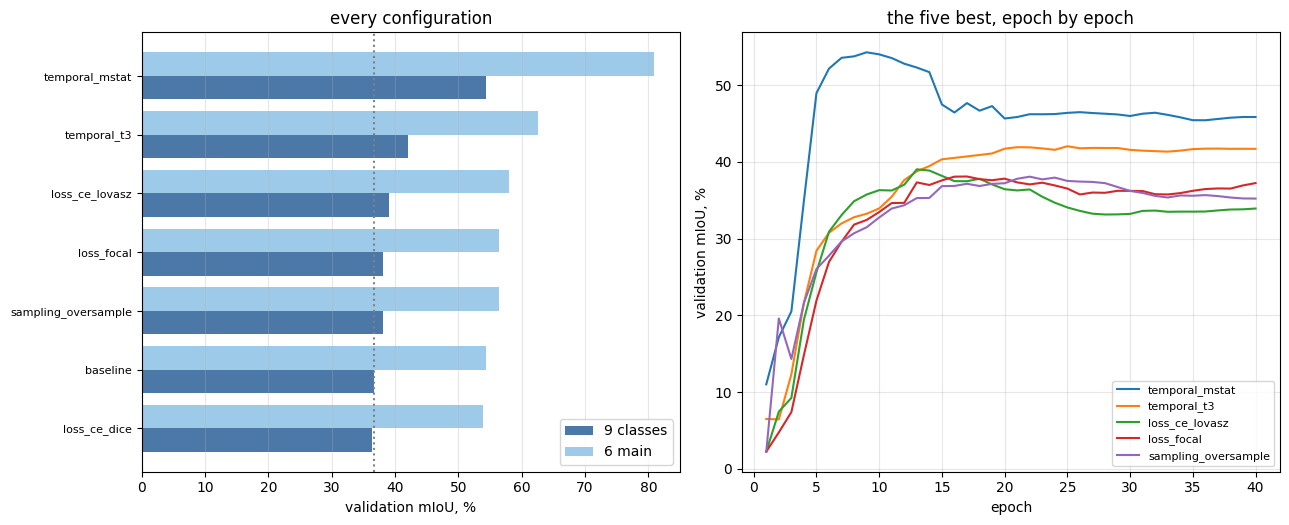

In [25]:
if runs:
    order = sorted(runs.values(), key=lambda r: -r["val"]["miou_9"])
    names = [r["name"] for r in order][::-1]
    nine = [100 * r["val"]["miou_9"] for r in order][::-1]
    main = [100 * r["val"]["miou_6_main"] for r in order][::-1]

    fig, (left, right) = plt.subplots(1, 2, figsize=(13, 0.45 * len(names) + 2.2))
    spot = np.arange(len(names))
    left.barh(spot - 0.2, nine, 0.4, label="9 classes", color="#4C78A8")
    left.barh(spot + 0.2, main, 0.4, label="6 main", color="#9ECAE9")
    left.set_yticks(spot, names, fontsize=8)
    left.set_xlabel("validation mIoU, %")
    left.set_title("every configuration")
    left.legend(); left.grid(alpha=0.3, axis="x")
    if "baseline" in runs:
        left.axvline(100 * runs["baseline"]["val"]["miou_9"], color="grey", linestyle=":")

    for r in order[:5]:
        right.plot([h["epoch"] for h in r["history"]],
                   [100 * h["val_miou_9"] for h in r["history"]], label=r["name"])
    right.set_xlabel("epoch"); right.set_ylabel("validation mIoU, %")
    right.set_title("the five best, epoch by epoch")
    right.legend(fontsize=8); right.grid(alpha=0.3)
    plt.tight_layout(); plt.show()

In [26]:
if runs:
    order = sorted(runs.values(), key=lambda r: -r["val"]["miou_9"])
    ref = runs.get("baseline")
    lengths = sorted({r.get("epochs", 0) for r in order})
    # Each row reports the epochs it was actually trained for. Taking it from the
    # current QUICK setting instead put 12-epoch rows under a 40-epoch heading.
    spell = (f"{lengths[0]} epochs per run" if len(lengths) == 1
             else f"**{', '.join(str(e) for e in lengths)} epochs - see the column, the rows "
                  f"are not all the same length**")
    lines = ["## N. Experiment sweep: what moves validation - "
             + time.strftime("%d %B %Y"),
             "",
             f"`notebooks/08_experiments.ipynb`, {spell}, SegFormer 2.3 M unless stated. "
             f"Every row shares one recipe; only the named thing changes.",
             "",
             "| run | channels | loss | epochs | val mIoU (9) | val (6 main) | test (9) | test (6 main) |",
             "|---|---|---|---|---|---|---|---|"]
    for r in order:
        test9 = f"{100 * r['test']['miou_9']:.1f}%" if "test" in r else "-"
        test6 = f"{100 * r['test']['miou_6_main']:.1f}%" if "test" in r else "-"
        lines.append(f"| {r['name']} | {r['in_channels']} | {r['loss']} | {r.get('epochs', '?')} | "
                     f"{100 * r['val']['miou_9']:.1f}% | {100 * r['val']['miou_6_main']:.1f}% | "
                     f"{test9} | {test6} |")
    if ref:
        best = order[0]
        lines += ["", f"Baseline on the current tiles: **{100 * ref['val']['miou_9']:.1f}%** "
                      f"(9 classes), {100 * ref['val']['miou_6_main']:.1f}% (6 main). "
                      f"Best: **{best['name']}**, "
                      f"{100 * (best['val']['miou_9'] - ref['val']['miou_9']):+.1f} points."]
    if load("cv"):
        cv = load("cv")
        lines += ["", f"Five-fold cross-validation over whole regions: "
                      f"**{100 * cv['miou_9_mean']:.1f}% +/- {100 * cv['miou_9_std']:.1f}** "
                      f"(9 classes). Differences smaller than that are noise."]
    report = "\n".join(lines)
    (EXP / "report.md").write_text(report, encoding="utf-8")
    print(report)
    print(f"\n\nwritten to {(EXP / 'report.md')}")

## N. Experiment sweep: what moves validation - 09 November 2026

`notebooks/08_experiments.ipynb`, 40 epochs per run, SegFormer 2.3 M unless stated. Every row shares one recipe; only the named thing changes.

| run | channels | loss | epochs | val mIoU (9) | val (6 main) | test (9) | test (6 main) |
|---|---|---|---|---|---|---|---|
| temporal_mstat | 9 | wce | 40 | 54.3% | 80.9% | 43.5% | 65.0% |
| temporal_t3 | 9 | wce | 40 | 42.1% | 62.6% | 27.2% | 40.8% |
| loss_ce_lovasz | 3 | ce_lovasz | 40 | 39.0% | 58.1% | 29.5% | 44.2% |
| loss_focal | 3 | focal | 40 | 38.1% | 56.5% | 27.5% | 41.2% |
| sampling_oversample | 3 | wce | 40 | 38.1% | 56.5% | 29.5% | 44.2% |
| baseline | 3 | wce | 40 | 36.6% | 54.3% | 27.4% | 41.2% |
| loss_ce_dice | 3 | ce_dice | 40 | 36.4% | 53.9% | 29.3% | 44.0% |

Baseline on the current tiles: **36.6%** (9 classes), 54.3% (6 main). Best: **temporal_mstat**, +17.7 points.


written to /home/jovyan/vault/exam/ECHOSCAPE/outputs/exp08/report.md


## Deliberately not in here

Worth knowing what this notebook does *not* answer, so the gaps are a choice rather than
an oversight:

- **DEM channels (elevation, slope, local incidence angle).** The clearest aim at the
  Death Valley failure — bare read as built-up 32% of the time, which is terrain geometry,
  not land cover. Left out because it needs a new download (Copernicus DEM from Planetary
  Computer) and a reprojection onto each region's radar grid; that is a pipeline change,
  not an experiment cell.
- **In-domain self-supervised pretraining** (MAE or BYOL on all 37 regions × 12 months of
  unlabelled radar). The strongest option in the literature for "few labelled scenes", and
  far too large to bolt on here.
- **Label quality.** Dynamic World's own confidence bands as soft targets, or a higher
  confidence floor than the current 0.35. This changes the labels, so every number in the
  table would move and nothing would be comparable. It deserves its own run.
- **Texture (GLCM) channels.** Cheap and aimed straight at trees-versus-cropland, but
  slow to compute per tile; `mstat` tests the same hypothesis more cheaply first.

And one thing that is a measurement problem rather than a modelling one: **validation holds
a few hundred snow pixels.** Experiment 0 prints the figure. No training change can raise a
class's IoU when the split barely contains it, so if the 9-class mean must be the headline,
the split needs a snow validation region — not a better model.